# Workshop 3 · Parte A · Pasos 3 y 4 — Feature engineering y modelo de regresión
Entrada: `data/processed/happiness_unified.csv` (salida de `eda.ipynb`).  
Salida: `models/model.pkl` (Pipeline scikit-learn: preprocesamiento + modelo), `models/metrics.json` y `data/streaming/happiness_stream.csv`.

In [1]:
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid")
ROOT = Path("..") if Path("../data").exists() else Path(".")
df = pd.read_csv(ROOT/"data/processed/happiness_unified.csv")
df.shape

(782, 9)

## Selección de features (y justificación)
| Decisión | Justificación |
|---|---|
| **Usar** `gdp, family, health, freedom, generosity, corruption` | Los 6 factores explicativos presentes en los 5 años y en el contrato del evento. |
| **No usar** `happiness_score` | Es el target. En el evento llega como `actual_happiness_score` y solo sirve para evaluar. |
| **No usar** `Dystopia Residual`, `Rank`, `Standard Error`, CI, `Whisker` | Se derivan del score (**fuga de target**) y no existen en todos los años ni en el evento. |
| **No usar** `region` | Solo existe en 2015–2016; el contrato del evento no la incluye. |
| **No usar** `country` | Es de alta cardinalidad y con split por país una dummy no generaliza; se usa como clave Kafka, no como feature. |
| **No usar** `year` | Identifica la observación, no explica la felicidad; el modelo debe funcionar con cualquier año. |
| **Sin categóricas** | Todas las features son numéricas: no hay encoding. |
| **`StandardScaler`** | Va dentro del `Pipeline` para que streaming aplique exactamente la transformación aprendida en entrenamiento. |

In [2]:
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
TARGET = "happiness_score"
X, y = df[FEATURES], df[TARGET]
assert TARGET not in FEATURES
df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)

gdp           0.789284
health        0.742456
family        0.648799
freedom       0.551258
corruption    0.400026
generosity    0.137578
Name: happiness_score, dtype: float64

## Split 70 / 30 por país
Un país aparece hasta 5 veces (una por año) y su score es muy estable. Un split aleatorio por fila dejaría al mismo país en train y test (**fuga entre filas**) e inflaría las métricas. Se usa `GroupShuffleSplit` agrupando por `country`.

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df["country"]))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
print(f"train={len(train_idx)} ({len(train_idx)/len(df):.0%})  test={len(test_idx)} ({len(test_idx)/len(df):.0%})")
print("países en común train∩test:", len(set(df.iloc[train_idx].country) & set(df.iloc[test_idx].country)))

train=542 (69%)  test=240 (31%)
países en común train∩test: 0


In [4]:
models = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}
def metrics(m, Xa, ya):
    p = m.predict(Xa)
    return dict(MAE=mean_absolute_error(ya, p), RMSE=float(np.sqrt(mean_squared_error(ya, p))), R2=r2_score(ya, p))
results, fitted = {}, {}
for name, est in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", est)]).fit(X_train, y_train)
    fitted[name] = pipe
    results[name] = {"train": metrics(pipe, X_train, y_train), "test": metrics(pipe, X_test, y_test)}
pd.DataFrame([{"model": n, **{f"{s}_{k}": round(v, 4) for s, d in r.items() for k, v in d.items()}}
              for n, r in results.items()]).set_index("model")

,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2
model,,,,,,
LinearRegression,0.4275,0.5427,0.7515,0.4318,0.5619,0.7838
DecisionTree,0.3285,0.4269,0.8462,0.5433,0.6828,0.6808
RandomForest,0.1341,0.1757,0.9740,0.4797,0.6124,0.7432


## Elección del modelo
El taller pide un modelo **simple** y se enfoca en integración, no en optimización. Se elige el de menor RMSE en test, y si la regresión lineal está a menos de 0.03 de RMSE del mejor, se prefiere por simplicidad/interpretabilidad.

In [5]:
best = min(results, key=lambda n: results[n]["test"]["RMSE"])
if results["LinearRegression"]["test"]["RMSE"] - results[best]["test"]["RMSE"] < 0.03:
    best = "LinearRegression"
print("Modelo elegido:", best)
pipeline = fitted[best]
results[best]["test"]

Modelo elegido: LinearRegression


{'MAE': 0.43184340166669594,
 'RMSE': 0.5618666977233481,
 'R2': 0.7838211678873233}

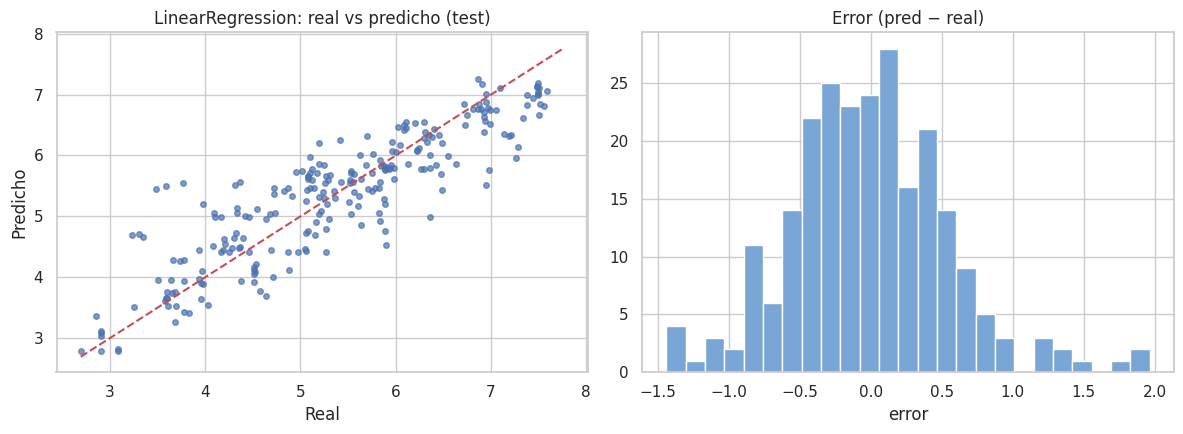

gdp           0.453
freedom       0.241
family        0.239
health        0.205
corruption    0.074
generosity    0.063
dtype: float64


In [6]:
pred = pipeline.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, s=16, alpha=.7); lim = [y.min(), y.max()]; ax[0].plot(lim, lim, "r--")
ax[0].set(xlabel="Real", ylabel="Predicho", title=f"{best}: real vs predicho (test)")
ax[1].hist(pred - y_test, bins=25, color="#7aa6d6"); ax[1].set(title="Error (pred − real)", xlabel="error")
plt.tight_layout(); plt.show()
if hasattr(pipeline[-1], "coef_"):
    print(pd.Series(pipeline[-1].coef_, index=FEATURES).sort_values(ascending=False).round(3))

## Serialización del pipeline completo (scaler + modelo)

In [7]:
(ROOT/"models").mkdir(exist_ok=True)
joblib.dump(pipeline, ROOT/"models/model.pkl")
report = {"chosen_model": best, "features": FEATURES, "target": TARGET,
          "split": "GroupShuffleSplit by country, 70/30, seed=42",
          "n_train": int(len(train_idx)), "n_test": int(len(test_idx)),
          "metrics": {n: {s: {k: round(v, 4) for k, v in d.items()} for s, d in r.items()} for n, r in results.items()}}
(ROOT/"models/metrics.json").write_text(json.dumps(report, indent=2))
reloaded = joblib.load(ROOT/"models/model.pkl")
assert np.allclose(reloaded.predict(X_test), pred)
print("Features que espera el modelo (orden):", list(reloaded.feature_names_in_))

Features que espera el modelo (orden): ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']


## Dataset para el productor de streaming
Se guarda el dataset preparado con una columna `split` para que el productor pueda emitir todo o solo el conjunto de test (países que el modelo no vio).

In [8]:
stream = df.copy(); stream["split"] = "train"; stream.loc[stream.index[test_idx], "split"] = "test"
stream = stream.sample(frac=1, random_state=7).reset_index(drop=True)
stream.to_csv(ROOT/"data/streaming/happiness_stream.csv", index=False)
stream["split"].value_counts()

split
train    542
test     240
Name: count, dtype: int64